# ProductPulse — Exploratory Analysis

Retention heatmap, user segmentation, revenue trends, and correlation
analysis against the loaded Postgres data. This notebook reads — it doesn't
regenerate anything (that's `01_data_cleaning_and_generation.ipynb`).


**Review note:** Saved outputs predate the current review and have not been regenerated. This project uses outcome-conditioned synthetic behavior and reconstructed billing dates. Model scores and business interpretations are illustrative; see [known limitations](../docs/project_review.md).

## Setup

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import URL, create_engine, text

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

load_dotenv('../.env')
db_url = URL.create(
    'postgresql+psycopg2',
    username=os.getenv('PGUSER'),
    password=os.getenv('PGPASSWORD', ''),
    host=os.getenv('PGHOST', 'localhost'),
    port=int(os.getenv('PGPORT', '5432')),
    database=os.getenv('PGDATABASE'),
)
engine = create_engine(db_url)

def run_sql_file(path):
    with open(path) as f:
        return pd.read_sql(text(f.read()), engine)

df = run_sql_file('../sql/features/user_features.sql')
print(df.shape)
df.head()


(9156, 15)


,user_id,signup_date,country,acquisition_channel,plan,status,converted,is_churned,total_payments,total_revenue,total_events,total_sessions,distinct_features_used,tenure_days,recency_days
0,0002-ORFBO,2025-12-03,United States,Partner,Pro,active,True,False,9,590.4,68,21,9,284,21
1,0003-MKNFE,2025-11-21,Germany,Referral,Pro,active,True,False,9,539.1,107,33,10,296,18
2,0004-TLHLJ,2023-07-10,United States,Paid Social,Pro,churned,True,True,4,295.6,43,13,7,1161,1028
3,0011-IGKFF,2021-11-12,Australia,Referral,Enterprise,churned,True,True,13,1274.0,279,75,10,1766,1372
4,0013-EXCHZ,2025-09-20,United States,Paid Search,Pro,churned,True,True,3,251.7,42,10,8,358,264


## Data quality check

Before drawing any conclusions from this table, confirm it's actually
complete and sane — the same discipline as Module 3's QA checks.


In [2]:
print("Missing values:")
print(df.isna().sum()[df.isna().sum() > 0])
print()
print(f"{(df['total_events'] == 0).sum()} users ({(df['total_events'] == 0).mean():.1%}) never generated a single event")
print(f"{df['converted'].sum()} converted to paid ({df['converted'].mean():.1%})")
df.describe(include='all').T


Missing values:
Series([], dtype: int64)

1737 users (19.0%) never generated a single event
7043 converted to paid (76.9%)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,9156,9156,0002-ORFBO,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
signup_date,9156,2002,2020-08-29,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,9156,10,United States,3804,NaN,NaN,NaN,NaN,NaN,NaN,NaN
acquisition_channel,9156,6,Organic Search,2533,NaN,NaN,NaN,NaN,NaN,NaN,NaN
plan,9156,3,Basic,3503,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,9156,2,active,5174,NaN,NaN,NaN,NaN,NaN,NaN,NaN
converted,9156,2,True,7043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_churned,9156,2,False,5174,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_payments,9156.0,NaN,NaN,NaN,24.900612,25.495028,0.0,1.0,15.0,48.0,72.0
total_revenue,9156.0,NaN,NaN,NaN,1753.504964,2206.306901,0.0,24.3625,734.45,2840.7625,8550.0


## Distributions

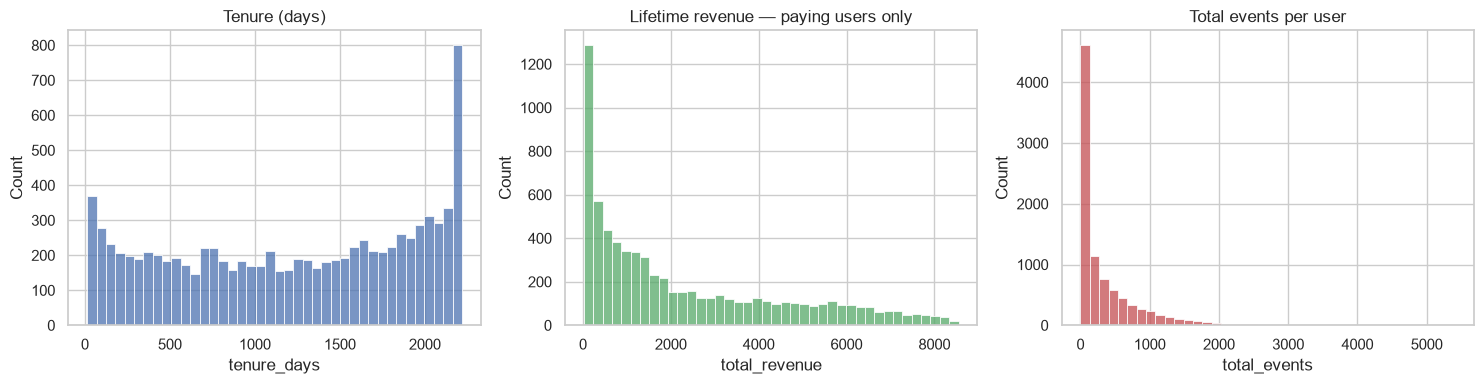

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['tenure_days'], bins=40, ax=axes[0], color='#4C72B0')
axes[0].set_title('Tenure (days)')
sns.histplot(df.loc[df['total_revenue'] > 0, 'total_revenue'], bins=40, ax=axes[1], color='#55A868')
axes[1].set_title('Lifetime revenue — paying users only')
sns.histplot(df['total_events'], bins=40, ax=axes[2], color='#C44E52')
axes[2].set_title('Total events per user')
plt.tight_layout()
plt.show()


## Retention Heatmap

The cohort×period matrix from `08_cohort_analysis.sql`, pivoted for a
standard cohort retention heatmap. Period 0 reads artificially low for every
cohort — that's a real, well-known artifact of month-bucketed cohorts, not a
bug: someone who signs up on the 25th only has a few days left in their
signup month to generate an event, versus a full 30 days for period 1.


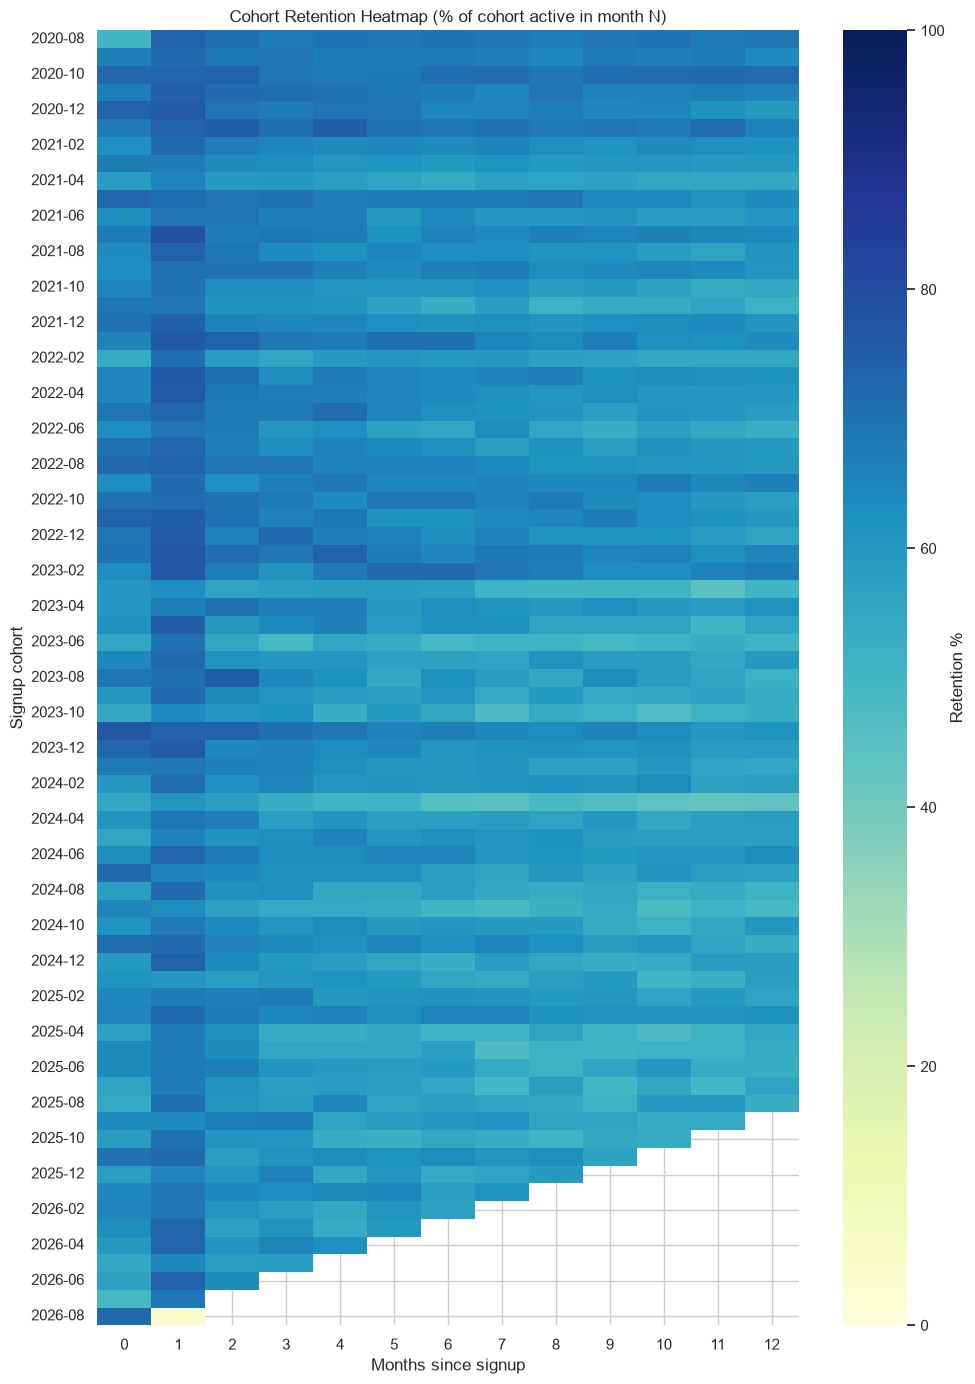

Average retention by period across all cohorts:
period_number
0     64.0
1     69.8
2     65.2
3     63.6
4     62.8
5     61.6
6     61.1
7     60.5
8     60.0
9     59.4
10    59.1
11    58.3
12    58.4
dtype: float64


In [4]:
cohort_df = run_sql_file('../sql/analysis/08_cohort_analysis.sql')
cohort_df['cohort_month'] = pd.to_datetime(cohort_df['cohort_month']).dt.strftime('%Y-%m')

pivot = cohort_df.pivot(index='cohort_month', columns='period_number', values='retention_pct')

plt.figure(figsize=(10, 14))
sns.heatmap(pivot, cmap='YlGnBu', vmin=0, vmax=100, cbar_kws={'label': 'Retention %'})
plt.title('Cohort Retention Heatmap (% of cohort active in month N)')
plt.xlabel('Months since signup')
plt.ylabel('Signup cohort')
plt.tight_layout()
plt.show()

print("Average retention by period across all cohorts:")
print(pivot.mean(axis=0).round(1))


## User Segmentation

Rule-based, not clustered — this project's tech stack scopes scikit-learn to
Logistic Regression only (used for the churn model in the next notebook), so
segmentation here uses transparent, explainable business rules instead of an
unsupervised algorithm. That's also usually the right call for segments a
product/marketing team needs to act on directly: "top 15% by weekly usage"
is something a PM can immediately do something with; a k-means cluster label
often isn't.


In [5]:
df['weeks_observed'] = (df['tenure_days'] / 7).clip(lower=1)
df['events_per_week'] = df['total_events'] / df['weeks_observed']

engaged_mask = df['total_events'] > 0
median_epw, p85_epw = df.loc[engaged_mask, 'events_per_week'].quantile([0.5, 0.85]).values

conditions = [
    df['total_events'] == 0,
    df['status'] == 'churned',
    df['events_per_week'] >= p85_epw,
    df['events_per_week'] >= median_epw,
]
choices = ['Never Activated', 'Churned', 'Power User', 'Regular User']
df['segment'] = np.select(conditions, choices, default='Casual User')

seg_summary = df.groupby('segment').agg(
    users=('user_id', 'count'),
    avg_revenue=('total_revenue', 'mean'),
    churn_rate=('is_churned', 'mean'),
    avg_events_per_week=('events_per_week', 'mean'),
).sort_values('users', ascending=False)
seg_summary['pct_of_users'] = (seg_summary['users'] / len(df) * 100).round(1)
seg_summary


,users,avg_revenue,churn_rate,avg_events_per_week,pct_of_users
segment,,,,,
Churned,2245,1275.089933,1.0,1.144821,24.5
Regular User,2197,2992.101661,0.0,2.704015,24.0
Casual User,1997,1094.940561,0.0,1.099348,21.8
Never Activated,1737,0.000000,1.0,0.000000,19.0
Power User,980,4522.725408,0.0,5.716051,10.7


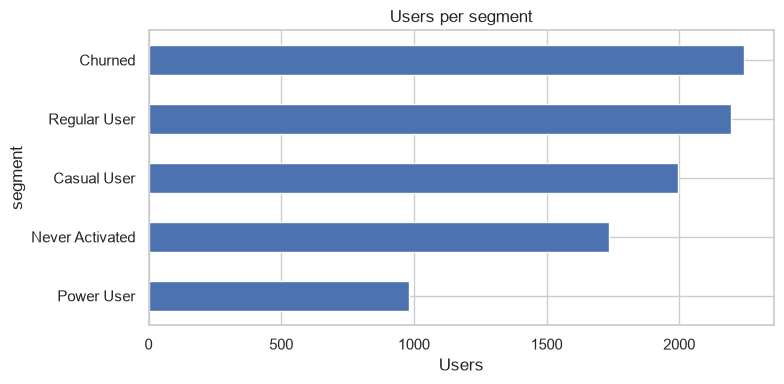

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
seg_summary['users'].sort_values().plot(kind='barh', ax=ax, color='#4C72B0')
ax.set_title('Users per segment')
ax.set_xlabel('Users')
plt.tight_layout()
plt.show()


## Revenue Trends

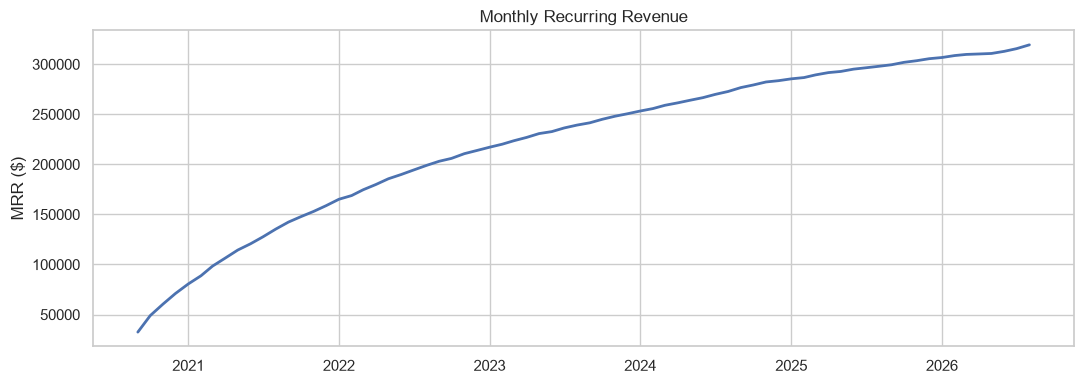

MRR grew from $32,480 to $319,395 over 72 months


In [7]:
mrr_df = run_sql_file('../sql/analysis/03_monthly_recurring_revenue.sql')
mrr_df['revenue_month'] = pd.to_datetime(mrr_df['revenue_month'])

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(mrr_df['revenue_month'], mrr_df['mrr'], color='#4C72B0', linewidth=2)
ax.set_title('Monthly Recurring Revenue')
ax.set_ylabel('MRR ($)')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.show()

print(f"MRR grew from ${mrr_df['mrr'].iloc[0]:,.0f} to ${mrr_df['mrr'].iloc[-1]:,.0f} "
      f"over {len(mrr_df)} months")


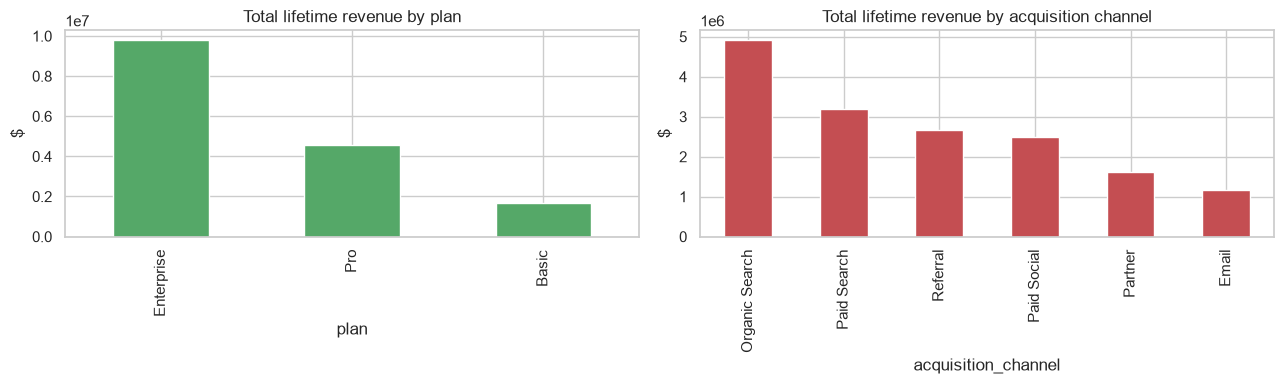

In [8]:
rev_by_plan = df.groupby('plan')['total_revenue'].sum().sort_values(ascending=False)
rev_by_channel = df.groupby('acquisition_channel')['total_revenue'].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
rev_by_plan.plot(kind='bar', ax=axes[0], color='#55A868')
axes[0].set_title('Total lifetime revenue by plan')
axes[0].set_ylabel('$')
rev_by_channel.plot(kind='bar', ax=axes[1], color='#C44E52')
axes[1].set_title('Total lifetime revenue by acquisition channel')
axes[1].set_ylabel('$')
plt.tight_layout()
plt.show()


## Correlation Analysis

How engagement and revenue signals relate to churn — this is exactly the
feature set the churn model in the next notebook will draw on, so this is
also a preview of what it will likely find important.


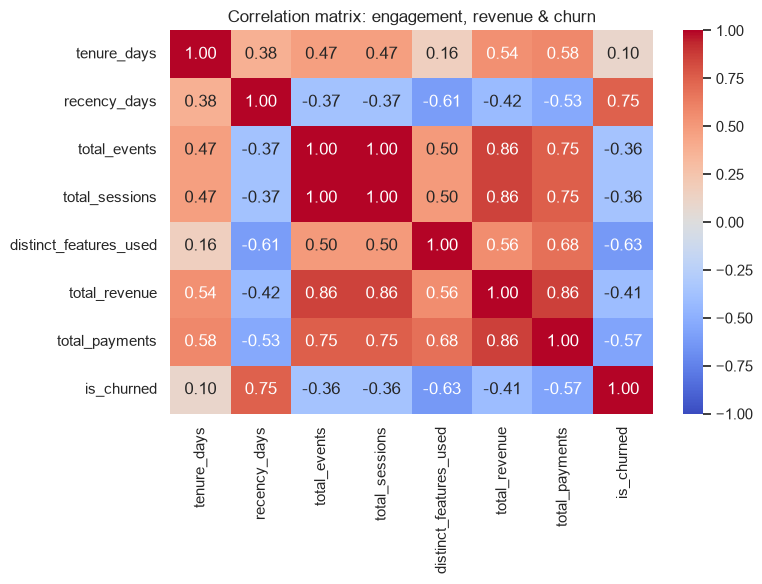

Correlation with is_churned, sorted:
distinct_features_used   -0.628486
total_payments           -0.566481
total_revenue            -0.411413
total_sessions           -0.360881
total_events             -0.360186
tenure_days               0.098410
recency_days              0.746184
Name: is_churned, dtype: float64


In [9]:
corr_cols = ['tenure_days', 'recency_days', 'total_events', 'total_sessions',
             'distinct_features_used', 'total_revenue', 'total_payments']
corr_df = df[corr_cols + ['is_churned']].copy()
corr_df['is_churned'] = corr_df['is_churned'].astype(int)
corr_matrix = corr_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation matrix: engagement, revenue & churn')
plt.tight_layout()
plt.show()

print("Correlation with is_churned, sorted:")
print(corr_matrix['is_churned'].drop('is_churned').sort_values())


### Reading this in business language

- **Recency is the strongest signal by far**: how long it's been since a user
  last showed up correlates positively with churn more than anything else
  here. That's the single most actionable early-warning sign — "haven't seen
  this account in N days" is something a customer-success team can act on
  well before the cancellation happens.
- **Engagement breadth and depth (events, sessions, distinct features used)
  correlate negatively with churn**: users who explore more of the product
  are stickier. This is the same story `09_feature_adoption.sql` told at the
  feature level, showing up again at the user level.
- **Revenue and payment count are only weakly related to churn on their
  own** — plan tier and dollar amount matter less than whether the person is
  still actually opening the product. Worth keeping in mind for Module 7:
  behavioral features are likely to outweigh billing features in the model.
